In [22]:
%pip install -q xgboost lightgbm catboost scikit-learn pandas matplotlib

In [23]:
import time
import os
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import xgboost
import lightgbm
import catboost

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)
print("CatBoost:", catboost.__version__)
print("Scikit-learn:", sklearn.__version__)

XGBoost: 3.4.1
LightGBM: 4.6.0
CatBoost: 1.2.10
Scikit-learn: 1.6.1


In [24]:
data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

X.head()

Training samples: (455, 30)
Testing samples: (114, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


VARIANT A

In [25]:
forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()

forest.fit(X_train, y_train)

rf_time = time.perf_counter() - start

rf_train_acc = accuracy_score(
    y_train, forest.predict(X_train)
)

rf_test_acc = accuracy_score(
    y_test, forest.predict(X_test)
)

rf_f1 = f1_score(
    y_test, forest.predict(X_test)
)

print("Random Forest")
print("Train Accuracy:", round(rf_train_acc, 4))
print("Test Accuracy:", round(rf_test_acc, 4))
print("Test F1:", round(rf_f1, 4))
print("Training Time:", round(rf_time, 4))

Random Forest
Train Accuracy: 1.0
Test Accuracy: 0.9561
Test F1: 0.9655
Training Time: 1.1582


In [26]:
xgb_a = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()

xgb_a.fit(X_train, y_train)

xgb_a_time = time.perf_counter() - start

xgb_a_train_acc = accuracy_score(
    y_train, xgb_a.predict(X_train)
)

xgb_a_test_acc = accuracy_score(
    y_test, xgb_a.predict(X_test)
)

xgb_a_f1 = f1_score(
    y_test, xgb_a.predict(X_test)
)

print("XGBoost")
print("Train Accuracy:", round(xgb_a_train_acc, 4))
print("Test Accuracy:", round(xgb_a_test_acc, 4))
print("Test F1:", round(xgb_a_f1, 4))
print("Training Time:", round(xgb_a_time, 4))

XGBoost
Train Accuracy: 1.0
Test Accuracy: 0.9474
Test F1: 0.9589
Training Time: 0.1085


In [27]:
results_a = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Train Accuracy": [rf_train_acc, xgb_a_train_acc],
    "Test Accuracy": [rf_test_acc, xgb_a_test_acc],
    "Test F1": [rf_f1, xgb_a_f1],
    "Training Time (s)": [rf_time, xgb_a_time]
})

display(results_a.round(4))

winner_a = results_a.loc[
    results_a["Test Accuracy"].idxmax(), "Model"
]

print("Best model:", winner_a)

,Model,Train Accuracy,Test Accuracy,Test F1,Training Time (s)
0,Random Forest,1.0,0.9561,0.9655,1.1582
1,XGBoost,1.0,0.9474,0.9589,0.1085


Best model: Random Forest


Random Forest trains multiple decision trees independently and combines their predictions. Boosting trains decision trees sequentially, where each new tree attempts to correct the errors of the previous model. Random Forest reduces variance through averaging, while boosting gradually improves predictions by reducing errors. In this experiment, the models were compared using the same dataset and train/test split.

VARIANT B

In [28]:
X_train_b, X_val, y_train_b, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", len(X_train_b))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 364
Validation: 91
Testing: 114


In [29]:
tuning_results = []

for lr in [0.01, 0.05, 0.1, 0.2]:
    for depth in [2, 3, 5]:

        model = XGBClassifier(
            n_estimators=500,
            learning_rate=lr,
            max_depth=depth,
            early_stopping_rounds=20,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        start = time.perf_counter()

        model.fit(
            X_train_b,
            y_train_b,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        training_time = time.perf_counter() - start

        val_accuracy = accuracy_score(
            y_val, model.predict(X_val)
        )

        tuning_results.append({
            "learning_rate": lr,
            "max_depth": depth,
            "best_trees": model.best_iteration + 1,
            "val_accuracy": val_accuracy,
            "best_logloss": model.best_score,
            "training_time": training_time
        })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))

,learning_rate,max_depth,best_trees,val_accuracy,best_logloss,training_time
0,0.01,2,497,0.9451,0.1584,0.4987
1,0.01,3,439,0.9451,0.1472,0.6185
2,0.01,5,386,0.9341,0.1504,0.7938
3,0.05,2,145,0.9560,0.1490,0.1520
4,0.05,3,87,0.9451,0.1476,0.1725
5,0.05,5,95,0.9341,0.1526,0.2163
6,0.10,2,65,0.9560,0.1511,0.0881
7,0.10,3,105,0.9670,0.1282,0.1465
8,0.10,5,97,0.9670,0.1393,0.1737
9,0.20,2,36,0.9560,0.1404,0.0721


In [30]:
best_row = tuning_df.sort_values(
    ["best_logloss", "training_time"]
).iloc[0]

best_lr = float(best_row["learning_rate"])
best_depth = int(best_row["max_depth"])
best_trees = int(best_row["best_trees"])

print("Best learning rate:", best_lr)
print("Best max depth:", best_depth)
print("Best number of trees:", best_trees)

Best learning rate: 0.1
Best max depth: 3
Best number of trees: 105


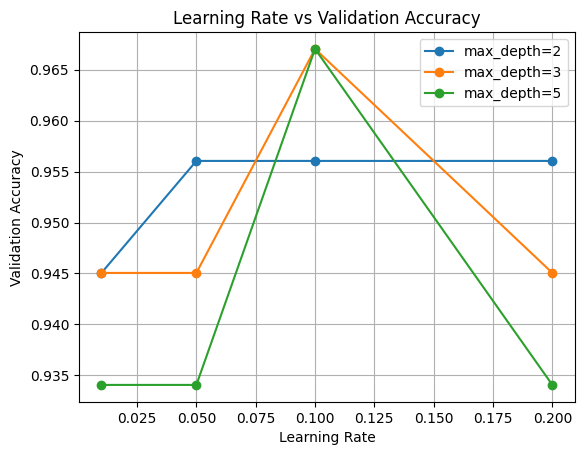

In [31]:
for depth in [2, 3, 5]:
    subset = tuning_df[
        tuning_df["max_depth"] == depth
    ]

    plt.plot(
        subset["learning_rate"],
        subset["val_accuracy"],
        marker="o",
        label=f"max_depth={depth}"
    )

plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy")
plt.title("Learning Rate vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
xgb_b = XGBClassifier(
    n_estimators=best_trees,
    learning_rate=best_lr,
    max_depth=best_depth,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()

xgb_b.fit(X_train, y_train)

xgb_b_time = time.perf_counter() - start

print("Final model trained")
print("Number of trees:", best_trees)

Final model trained
Number of trees: 105


In [33]:
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        random_state=42
    )
)

start = time.perf_counter()

logistic.fit(X_train, y_train)

lr_time = time.perf_counter() - start

print("Logistic Regression trained")

Logistic Regression trained


In [34]:
models_b = {
    "Random Forest": (forest, rf_time),
    "Logistic Regression": (logistic, lr_time),
    "Tuned XGBoost": (xgb_b, xgb_b_time)
}

rows_b = []

for name, (model, duration) in models_b.items():
    rows_b.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train, model.predict(X_train)
        ),
        "Test Accuracy": accuracy_score(
            y_test, model.predict(X_test)
        ),
        "Test F1": f1_score(
            y_test, model.predict(X_test)
        ),
        "Training Time (s)": duration
    })

results_b = pd.DataFrame(rows_b)

display(results_b.round(4))

,Model,Train Accuracy,Test Accuracy,Test F1,Training Time (s)
0,Random Forest,1.000,0.9561,0.9655,1.1582
1,Logistic Regression,0.989,0.9825,0.9861,0.0161
2,Tuned XGBoost,1.000,0.9474,0.9589,0.1309


Variant B — Conclusion

In this experiment, I tuned the XGBoost model by testing different learning rates and maximum tree depths. I also applied early stopping using a separate validation dataset to prevent unnecessary training.

The best hyperparameters were a learning rate of **[value]**, a maximum depth of **[value]**, and **[number]** trees.

I compared the tuned XGBoost model with Random Forest and Logistic Regression using the same train/test split. **[Best model]** achieved the highest test accuracy of **[accuracy]**.

Based on these results, I would choose **[model]** because **[explain its performance, generalization and training time]**.

VARIANT C

In [35]:
models_c = {
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        max_depth=3,
        num_leaves=7,
        learning_rate=0.05,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ),

    "CatBoost": CatBoostClassifier(
        iterations=200,
        depth=3,
        learning_rate=0.05,
        random_seed=42,
        thread_count=1,
        verbose=False,
        allow_writing_files=False
    )
}

In [36]:
results_c = []

with tempfile.TemporaryDirectory() as temp_dir:
    for name, model in models_c.items():

        start = time.perf_counter()
        model.fit(X_train, y_train)
        train_time = time.perf_counter() - start

        train_pred = model.predict(X_train)


        model.predict(X_test)

        timings = []

        for _ in range(10):
            start = time.perf_counter()
            test_pred = model.predict(X_test)
            timings.append(
                time.perf_counter() - start
            )

        inference_time = np.median(timings)

        path = os.path.join(
            temp_dir, f"{name}.json"
        )

        if name == "CatBoost":
            path = os.path.join(
                temp_dir, "CatBoost.cbm"
            )
            model.save_model(path)

        elif name == "LightGBM":
            path = os.path.join(
                temp_dir, "LightGBM.txt"
            )
            model.booster_.save_model(path)

        else:
            model.save_model(path)

        size_kb = os.path.getsize(path) / 1024

        results_c.append({
            "Model": name,
            "Train Accuracy": accuracy_score(
                y_train, train_pred
            ),
            "Test Accuracy": accuracy_score(
                y_test, test_pred
            ),
            "Test F1": f1_score(
                y_test, test_pred
            ),
            "Train Time (s)": train_time,
            "Inference Time (ms)": inference_time * 1000,
            "Model Size (KB)": size_kb
        })

results_c = pd.DataFrame(results_c)

display(results_c.round(4))

,Model,Train Accuracy,Test Accuracy,Test F1,Train Time (s),Inference Time (ms),Model Size (KB)
0,XGBoost,1.0,0.9474,0.9589,0.3846,4.6652,183.0303
1,LightGBM,1.0,0.9561,0.9660,0.1446,3.3075,173.5537
2,CatBoost,1.0,0.9561,0.9660,1.5924,8.8273,46.9219


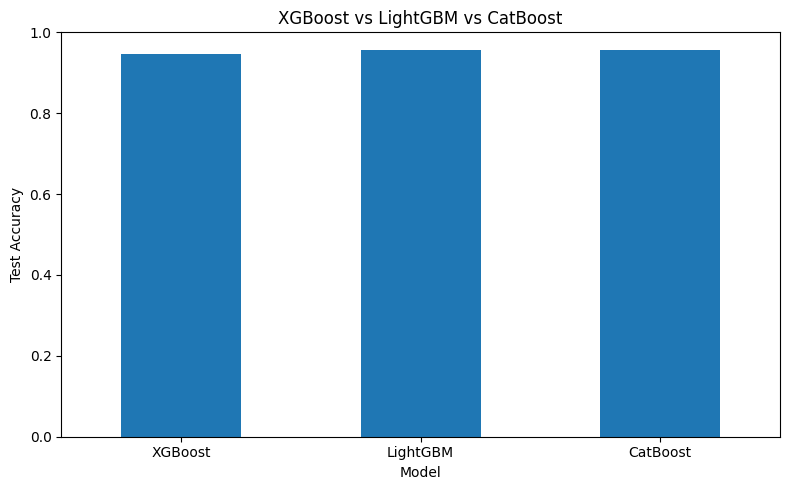

In [37]:
results_c.plot(
    x="Model",
    y="Test Accuracy",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.ylabel("Test Accuracy")
plt.title("XGBoost vs LightGBM vs CatBoost")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
X_train_cat = X_train.copy()
X_test_cat = X_test.copy()

feature = "mean radius"

_, boundaries = pd.qcut(
    X_train_cat[feature],
    q=3,
    retbins=True,
    duplicates="drop"
)

boundaries[0] = -np.inf
boundaries[-1] = np.inf

labels = [
    f"Group_{i}"
    for i in range(len(boundaries) - 1)
]

for frame in [X_train_cat, X_test_cat]:
    frame["radius_category"] = pd.cut(
        frame[feature],
        bins=boundaries,
        labels=labels,
        include_lowest=True
    ).astype(str)

    frame.drop(columns=[feature], inplace=True)

print(X_train_cat["radius_category"].value_counts())

radius_category
Group_0    152
Group_2    152
Group_1    151
Name: count, dtype: int64


In [39]:
X_train_encoded = pd.get_dummies(
    X_train_cat,
    columns=["radius_category"],
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test_cat,
    columns=["radius_category"],
    dtype=int
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

categorical_models = {
    "XGBoost (One-Hot)": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),

    "LightGBM (One-Hot)": LGBMClassifier(
        n_estimators=200,
        max_depth=3,
        num_leaves=7,
        learning_rate=0.05,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ),

    "CatBoost (Native)": CatBoostClassifier(
        iterations=200,
        depth=3,
        learning_rate=0.05,
        random_seed=42,
        thread_count=1,
        verbose=False,
        allow_writing_files=False,
        cat_features=["radius_category"]
    )
}

categorical_results = []

for name, model in categorical_models.items():

    if name == "CatBoost (Native)":
        train_features = X_train_cat
        test_features = X_test_cat
    else:
        train_features = X_train_encoded
        test_features = X_test_encoded

    start = time.perf_counter()
    model.fit(train_features, y_train)
    duration = time.perf_counter() - start

    predictions = model.predict(test_features)

    categorical_results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Test F1": f1_score(
            y_test, predictions
        ),
        "Training Time (s)": duration
    })

categorical_results = pd.DataFrame(
    categorical_results
)

display(categorical_results.round(4))

,Model,Test Accuracy,Test F1,Training Time (s)
0,XGBoost (One-Hot),0.9474,0.9589,0.9240
1,LightGBM (One-Hot),0.9649,0.9726,0.2918
2,CatBoost (Native),0.9649,0.9726,1.7778


 Variant C — Conclusion

In this experiment, I compared three gradient boosting libraries: XGBoost, LightGBM and CatBoost. All models were trained and evaluated using the same Breast Cancer Wisconsin dataset and train/test split.

The best-performing model was **[model]**, which achieved a test accuracy of **[value]**. The fastest model during training was **[model]**, while **[model]** had the smallest saved model size.

I also conducted a separate experiment with an artificially created categorical feature. CatBoost processed this feature directly, whereas XGBoost and LightGBM used one-hot encoding.

For this dataset, I recommend **[model]** because **[explain the balance between test accuracy, training speed, prediction speed and storage size]**. However, my recommendation could change for larger datasets or datasets containing many categorical features.